# Flow matching with transformer
This tutorial is part of the talk on the TUPHEDS Group Meeting on 28.10.2026.

- The flow-matching part is based on the [flow-matching notebook](https://github.com/lukasheinrich/generative_models_examples/blob/main/flowmatching/FlowMatching2D.ipynb) by Lukas Heinrich.
- The transformer part is based on the [GPT tutorial](https://www.youtube.com/watch?v=kCc8FmEb1nY) by Andrej Karpathy.
- Many ideas were learnt from the [codebase](https://github.com/lego-erc/FM-Transformer/tree/main) of Richard Hildebrandt.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
import sklearn.datasets as skld
import torch
import torch.nn as nn
from torch.nn import functional as F

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


We start by constructing: 

- the conditional velocity field $u_t(x \mid x_1)
= \frac{x_1 - (1 - \sigma_{\min})x}
{1 - (1 - \sigma_{\min})t}$
- the conditional flow $\psi_t(x \mid x_1)
= \left(1 - (1 - \sigma_{\min})t\right)x + tx_1$

 Source: Lipman et al. 2022, "Flow Matching for Generative Modeling" (arXiv:2210.02747)

We will test our model on the two-moons dataset

In [ ]:
Sigmin_2d = torch.tensor([0.01, 0.01], device=device)

# get conditional velocity field u_t(x|x_1)
def conditional_field(position, time, target, sigmin):
    return (target-(1-sigmin)*position)/(1-(1-sigmin)*time)

# get conditional flow psi_t(x)
def conditional_sample(noise, time, target, sigmin):
    sigma = 1-(1-sigmin)*time
    mean = time*target
    return sigma*noise + mean

def sample_data_2d(N=100):
    return torch.tensor(skld.make_moons(N, noise=0.05)[0], dtype=torch.float32, device=device)

The mask will be randomly chosen in the training.

Three different scenarios:
- Generate var2 conditioned on var1: $p(var2|var1)$
- Generate var1 conditioned on var2: $p(var1|var2)$
- Generate the joint distribution of var1 and var2: $p(var1,var2)$

In [4]:
masks = torch.tensor([
    [True, False], # first var known, second var unknown
    [False, True],
    [False, False], # both variables unknown
], device=device)

### Let's first build one from scratch!

In [5]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 10000
eval_interval = 500
n_embd = 64
n_heads = 4
n_layers = 4
dropout = 0
# ------------

#### Self-Attention and Transformer Building Blocks (Nothing New)

In [6]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        k = self.key(x)   # (B,T,H), H = head_size
        q = self.query(x) # (B,T,H)
        B,T,head_size = k.shape
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * head_size**-0.5 # (B, T, H) @ (B, H, T) -> (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,H)
        out = wei @ v # (B, T, T) @ (B, T, H) -> (B, T, H)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

#### Flow-Matching Encoder Transformer
We choose an encoder transformer, because our model uses non-causal attention.

Input:
- xt: [variables[0], variables[1], time]\
Known variables use their data value; unknown variables use the noisy value x_t.

- known: Optional, information about which variables are known

Output:
- Learned velocity field

In [ ]:
class Encoder_Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Linear(1, n_embd) # Since input is continuous, we use nn.Linear() instead of nn.Embedding()
        self.variable_embedding = nn.Embedding(3, n_embd) # Type of the token, (data[0], data[1], time)
        self.known_embedding = nn.Embedding(2, n_embd) # The flow should act different to the token, depending on if it's known

        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.vf_head = nn.Linear(n_embd, 1) # from embedding to velocity field

    def forward(self, xt, known=None):
        '''
        xt: (B, 3), xt[:, i] = [var1, var2, time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = xt.shape

        # known is the mask, known -> True, unknown -> False
        if known is None:
            known = torch.zeros((B, 2), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)
        
        # B = batch_size, T = dim_input, C = embedding_dimension
        tok_emb = self.token_embedding(xt.unsqueeze(-1)) # (B,T,C)
        var_emb = self.variable_embedding(torch.arange(T, device=device)) # (T,C)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        x = tok_emb + var_emb + kno_emb
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)

        velocity = self.vf_head(x).squeeze(-1)[:, :-1]  # (B,2), drop the output token for time

        return velocity.masked_fill(known, 0.0) # set the output of known var to zero -> flow does not move for known var


In [ ]:
# sanity check
m = Encoder_Transformer()
m = m.to(device)

test_input = torch.rand(16,3, device=device)
known = torch.tensor([False, True], device=device)
# known = masks[torch.randint(len(masks), (16,))]
output = m(test_input, known=known)
print(known[:10])
print(output[:10])
assert output.shape == (16, 2)

tensor([False,  True], device='cuda:0')
tensor([[-0.2867,  0.0000],
        [-0.2969,  0.0000],
        [-0.3084,  0.0000],
        [-0.3022,  0.0000],
        [-0.3122,  0.0000],
        [-0.3063,  0.0000],
        [-0.3009,  0.0000],
        [-0.3102,  0.0000],
        [-0.2925,  0.0000],
        [-0.3110,  0.0000]], device='cuda:0', grad_fn=<SliceBackward0>)


#### Flow-Matching Training

In [ ]:
def train_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    for i in range(max_iters):

        # sample noise, target, times and indices
        noise = torch.randn(batch_size, 2, device=device)
        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        indices = torch.randint(len(masks), (batch_size,), device=device)

        known_masks = masks[indices]
        positions = conditional_sample(noise, times, target, Sigmin_2d) # calculate cond flow at given times
        cond_field = conditional_field(positions, times, target, Sigmin_2d) # calculate cond VF for loss function
        positions = torch.where(known_masks, target, positions) # The input contains x_t for unknown var and target for known var

        xt = torch.column_stack([positions, times])
        model_field = model(xt, known=known_masks)

        unknown = ~known_masks
        loss = ((model_field - cond_field)**2 * unknown).sum() / unknown.sum() # The loss is a weighted loss combining all three masks
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            print(f"step {i}: train loss {loss:.4f}")
    return model


In [13]:
vf = Encoder_Transformer()
vf = vf.to(device)

vf = train_transformer_FM(vf)

step 0: train loss 5.4106
step 500: train loss 0.7753
step 1000: train loss 0.7732
step 1500: train loss 0.7286
step 2000: train loss 0.7913
step 2500: train loss 0.8452
step 3000: train loss 0.7616
step 3500: train loss 0.7549
step 4000: train loss 0.7067
step 4500: train loss 0.7478
step 5000: train loss 0.6368
step 5500: train loss 0.7114
step 6000: train loss 0.7856
step 6500: train loss 0.7339
step 7000: train loss 0.7764
step 7500: train loss 0.7706
step 8000: train loss 0.8337
step 8500: train loss 0.7411
step 9000: train loss 0.7151
step 9500: train loss 0.7126
step 9999: train loss 0.7082


#### Sampling


##### Generate both coordinates

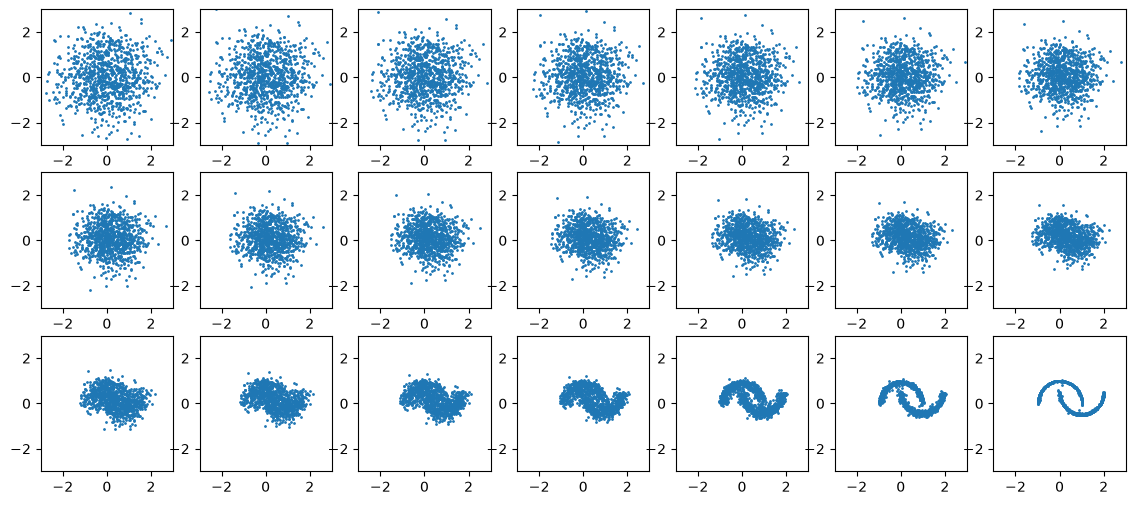

In [14]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21, device=device)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)),
                torch.randn(1000,2, device=device), tint)
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

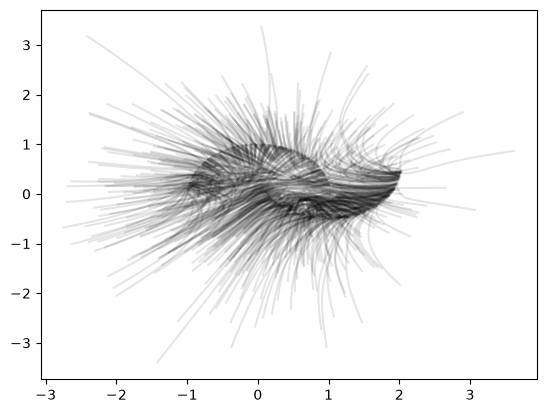

In [15]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

##### How about conditional generation?

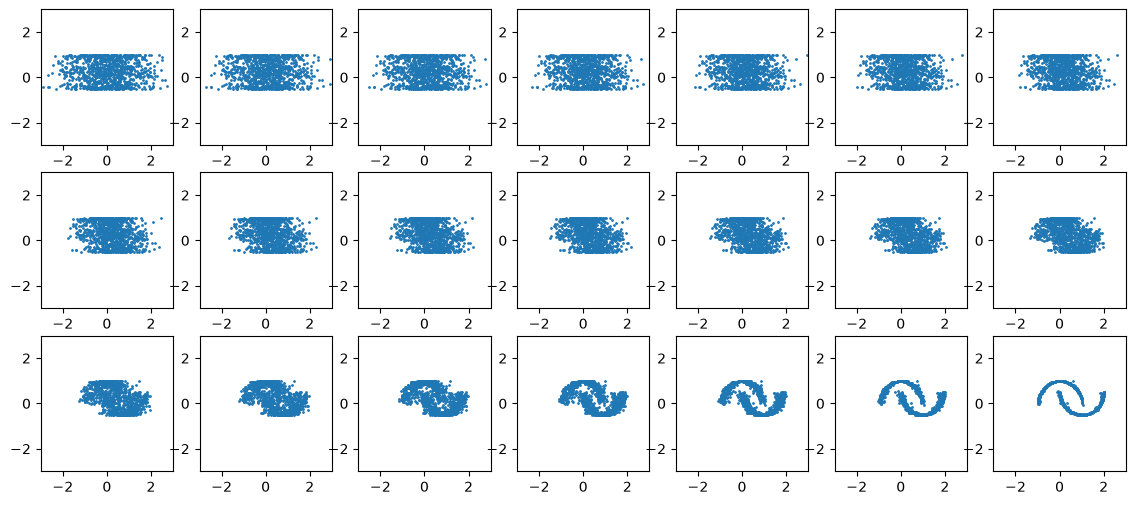

In [17]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21, device=device)
    known = [False, True] # provide a mask
    target = sample_data_2d(1000)[:,1].unsqueeze(-1)
    positions = torch.cat([torch.randn(1000,1, device=device),target],dim=-1)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, tint)
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

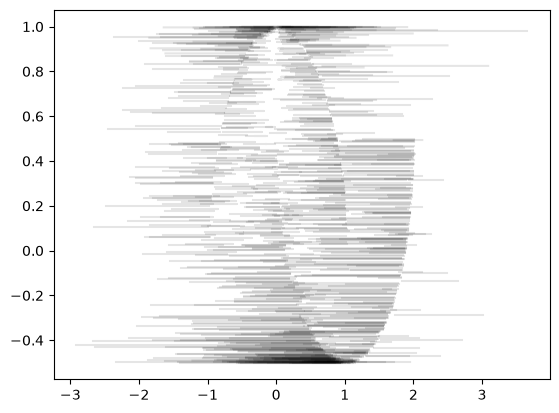

In [18]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

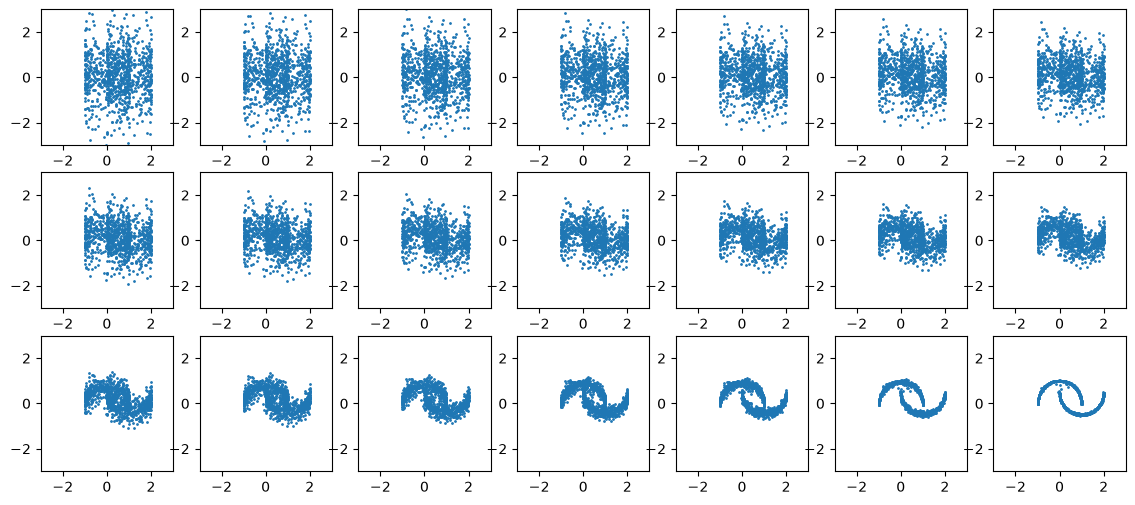

In [19]:
vf.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21, device=device)
    known = [True, False]
    target = sample_data_2d(1000)[:,0].unsqueeze(-1)
    positions = torch.cat([target,torch.randn(1000,1, device=device)],dim=-1)
    xint = odeint(lambda t, x:vf(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, tint)
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

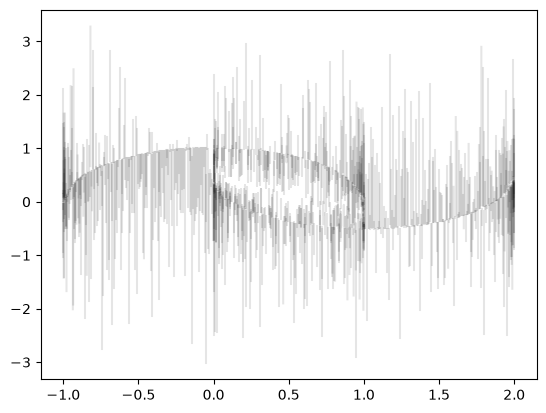

In [20]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

In [ ]:
vf.eval()
with torch.no_grad():
    a = 0.5
    known = [True, False]
    x_init = torch.cat([torch.full((1000, 1), a, device=device),
                        torch.randn(1000, 1, device=device)], dim=-1)
    xint = odeint(lambda t, x: vf(torch.cat([x, torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                  x_init, torch.linspace(0, 1, 21, device=device))

data = sample_data_2d(100_000).cpu()
band = data[(data[:, 0] - a).abs() < 0.05, 1]
plt.hist(xint[-1, :, 1].cpu().numpy(), bins=60, density=True, histtype='step', label=f'model: p(var2 | var1={a})')
plt.hist(band.numpy(), bins=60, density=True, histtype='step', label=f'data: |var1-{a}|<0.05')
plt.legend(); plt.show()

### The same setup using packages
The packages used are x-transformers & flow-matching packages.
They will not be discussed in the talk, but serve as an example if you are interested.

In [ ]:
%pip install x-transformers flow_matching
# x-transformers requires torch ≥ 2.5

In [ ]:
from flow_matching.path.scheduler import CondOTScheduler
from flow_matching.path import AffineProbPath
from flow_matching.solver import ODESolver
from flow_matching.utils import ModelWrapper

from x_transformers import ContinuousTransformerWrapper, Encoder

In [ ]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 10000
eval_interval = 500
n_embd = 64
n_heads = 4
n_layers = 4
dropout = 0
# ------------

In [ ]:
# Transformer Backbone

class Encoder_x_Transformer(nn.Module):
    def __init__(self, n_embd=n_embd, n_layers=n_layers, n_heads=n_heads):
        super().__init__()
        self.known_embedding = nn.Embedding(2, n_embd) # This will be passed to x-transformer as sum_embeds

        self.transformer = ContinuousTransformerWrapper(
            dim_in = 1,
            dim_out = 1,
            max_seq_len = 3,
            attn_layers = Encoder(
                dim = n_embd,
                depth = n_layers,
                heads = n_heads
            )
)

    def forward(self, xt, known=None):
        '''
        xt: (B, 3), xt[:, i] = [var1, var2, time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = xt.shape

        if known is None:
            known = torch.zeros((B, 2), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        velocity = self.transformer(xt.unsqueeze(-1), sum_embeds=kno_emb)
        velocity = velocity.squeeze(-1)[:, :-1]  # (B,2)

        return velocity.masked_fill(known, 0.0)

In [24]:
path = AffineProbPath(scheduler=CondOTScheduler())

In [ ]:
def train_x_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    for i in range(max_iters):

        # sample noise, target, times and indices
        noise = torch.randn(batch_size, 2, device=device)
        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        indices = torch.randint(len(masks), (batch_size,), device=device)

        known_masks = masks[indices]
        path_sample = path.sample(x_0=noise, x_1=target, t=times.squeeze(-1))
        positions = torch.where(known_masks, target, path_sample.x_t)
        xt = torch.column_stack([positions, times])
        model_field = model(xt, known=known_masks)

        unknown = ~known_masks
        loss = ((model_field - path_sample.dx_t)**2 * unknown).sum() / unknown.sum()
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            print(f"step {i}: train loss {loss:.4f}")
    return model


vf_x = Encoder_x_Transformer() # x refers to the package x_transformer
vf_x = vf_x.to(device)

vf_x.train()
vf_x = train_x_transformer_FM(vf_x)

step 0: train loss 1.3795
step 500: train loss 0.8193
step 1000: train loss 0.7210
step 1500: train loss 0.7604
step 2000: train loss 0.7595
step 2500: train loss 0.7387
step 3000: train loss 0.7487
step 3500: train loss 0.8043
step 4000: train loss 0.7257
step 4500: train loss 0.8009
step 5000: train loss 0.7648
step 5500: train loss 0.6873
step 6000: train loss 0.6914
step 6500: train loss 0.6827
step 7000: train loss 0.6585
step 7500: train loss 0.7100
step 8000: train loss 0.6814
step 8500: train loss 0.7008
step 9000: train loss 0.6730
step 9500: train loss 0.6990
step 9999: train loss 0.7217


##### Sampling

In [26]:
class WrappedModel(ModelWrapper):
    def forward(self, x: torch.Tensor, t: torch.Tensor, **extras):
        xt = torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)
        return self.model(xt, **extras)

In [27]:
# step size for ode solver
step_size = 0.05

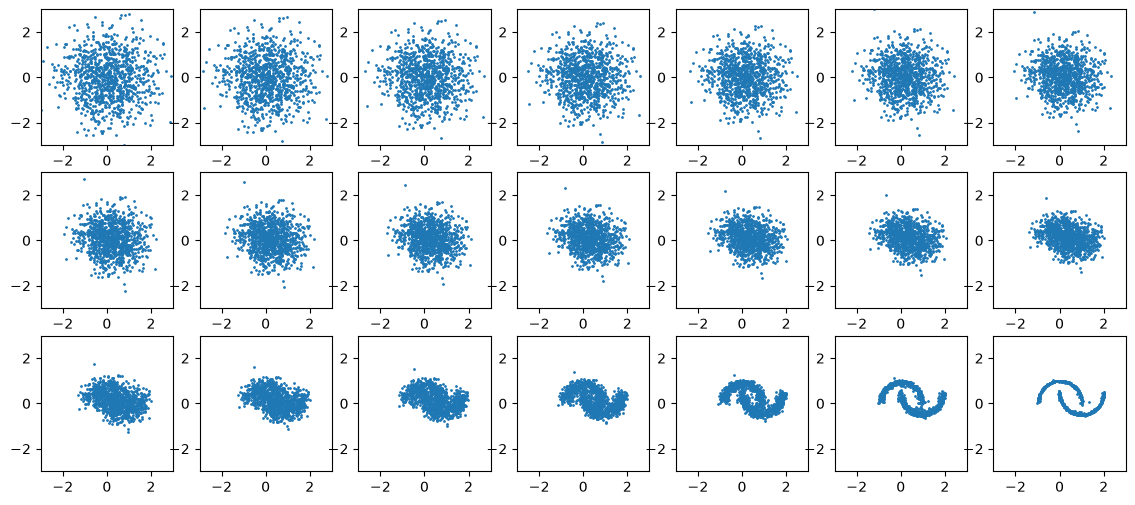

In [ ]:
with torch.no_grad():
    T = torch.linspace(0.0,1.0,21, device=device)
    x_init = torch.randn(1000,2, device=device)
    solver = ODESolver(velocity_model=WrappedModel(vf_x.eval()))  # create an ODESolver class
    xint = solver.sample(time_grid=T, x_init=x_init, method='midpoint', step_size=step_size, return_intermediates=True)  # sample from the model
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

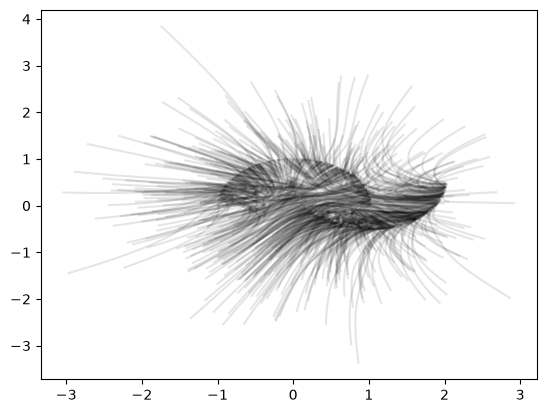

In [29]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)
plt.show()

Outlook:
- Use sinusoidal time embedding
- Use adaptive Layer Normalization
- Calculate per-mask validation
- ...